In [1]:
import pandas as pd
import yfinance as yf
import numpy as np
from datetime import timedelta
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import warnings
import time
import random
warnings.filterwarnings('ignore') # Para que no salgan textos rojos molestos de Pandas

# ==============================================================================
# 1. CARGA DE DATOS Y NUEVAS VARIABLES
# ==============================================================================
print("1. Cargando datos institucionales (Solo Acciones y Opciones)...")
# Ajusta el nombre si tu archivo final se llama distinto
df = pd.read_csv('../2020-2025PP.csv') 

# Aseguramos fechas sin zonas horarias y creamos el "Mes"
df['Buy_Date'] = pd.to_datetime(df['Notif_Date'], errors='coerce').dt.tz_localize(None)
df['Sell_Date'] = df['Buy_Date'] + timedelta(days=19)
df['Mes_Operacion'] = df['Buy_Date'].dt.month

1. Cargando datos institucionales (Solo Acciones y Opciones)...


In [2]:
# ==============================================================================
# DIAGNÓSTICO DE LA HEMORRAGIA DE DATOS
# ==============================================================================
print(f"Total de filas que llegan al Notebook: {len(df)}")

print("\n--- RECUENTO DE VALORES NULOS POR COLUMNA ---")
columnas_sospechosas = [
    'Return_19d', 'Return_SPY_19d', 'Sector', 'Amount_Num', 
    'Diferencia_Dias', 'SPY_Trend', 'Name', 'Owner', 'Op_Type',
    'Operaciones_Ultimos_30d', 'Compradores_Mismo_Ticker_15d', 'Mes_Operacion'
]

for col in columnas_sospechosas:
    if col in df.columns:
        nulos = df[col].isna().sum()
        if nulos > 0:
            print(f"🔴 {col}: {nulos} filas nulas (¡Peligro!)")
        else:
            print(f"🟢 {col}: 0 nulos (Limpia)")

Total de filas que llegan al Notebook: 12352

--- RECUENTO DE VALORES NULOS POR COLUMNA ---
🟢 Sector: 0 nulos (Limpia)
🔴 Amount_Num: 1 filas nulas (¡Peligro!)
🟢 Diferencia_Dias: 0 nulos (Limpia)
🟢 SPY_Trend: 0 nulos (Limpia)
🟢 Name: 0 nulos (Limpia)
🔴 Owner: 6058 filas nulas (¡Peligro!)
🟢 Op_Type: 0 nulos (Limpia)
🟢 Operaciones_Ultimos_30d: 0 nulos (Limpia)
🟢 Compradores_Mismo_Ticker_15d: 0 nulos (Limpia)
🟢 Mes_Operacion: 0 nulos (Limpia)


In [3]:
# ==============================================================================
# 2. EL VEREDICTO (CALCULAR EL ÉXITO A 19 DÍAS) - MODO ANTI-BLOQUEO
# ==============================================================================

print("2. Descargando precios de mercado (Modo Secuencial Anti-Bloqueo)...")
print("   Esto tardará unos minutos, pero asegurará que no perdamos datos.")

tickers = df['Acronym'].dropna().unique().tolist()
# Nos aseguramos de incluir el SPY
if 'SPY' not in tickers:
    tickers.append('SPY')

hist_data_dict = {}

# Descargamos uno a uno con sigilo
for i, ticker in enumerate(tickers):
    intentos = 0
    while intentos < 3:
        try:
            # Descarga de un solo ticker
            temp = yf.download(ticker, start="2019-01-01", progress=False, auto_adjust=True)
            
            # Si Yahoo devuelve datos, guardamos solo la columna 'Close' (Cierre)
            if not temp.empty:
                # Manejo seguro por si yfinance cambia el formato
                if isinstance(temp.columns, pd.MultiIndex):
                    hist_data_dict[ticker] = temp['Close'][ticker]
                else:
                    hist_data_dict[ticker] = temp['Close']
            
            # Si ha ido bien, salimos del bucle while y pasamos al siguiente ticker
            break 
            
        except Exception:
            intentos += 1
            time.sleep(2) # Pausa larga si nos bloquean
            
    # Imprimir progreso para no desesperarnos
    if (i + 1) % 50 == 0:
        print(f"   Descargados {i + 1}/{len(tickers)} tickers...")
        
    # La clave del éxito: pausa aleatoria entre cada petición
    time.sleep(random.uniform(0.1, 0.4))

# Juntamos todas las series en un único DataFrame gigante
print("   Construyendo la matriz de precios...")
hist_data = pd.DataFrame(hist_data_dict)

def get_price(ticker, target_date, method='forward'):
    if ticker not in hist_data.columns: return np.nan
    series = hist_data[ticker].dropna()
    if series.empty: return np.nan
    try:
        # Busca el precio más cercano. 'forward' para la compra, 'nearest' para venta.
        idx = series.index.get_indexer([target_date], method='bfill' if method=='forward' else 'nearest')[0]
        if idx != -1 and idx < len(series): return series.iloc[idx]
    except: return np.nan
    return np.nan

print("   Calculando quién batió al S&P 500...")
df['Buy_Price'] = df.apply(lambda row: get_price(row['Acronym'], row['Buy_Date'], 'forward'), axis=1)
df['Sell_Price'] = df.apply(lambda row: get_price(row['Acronym'], row['Sell_Date'], 'nearest'), axis=1)
df['Return_19d'] = (df['Sell_Price'] - df['Buy_Price']) / df['Buy_Price']

df['SPY_Buy'] = df['Buy_Date'].apply(lambda x: get_price('SPY', x, 'forward'))
df['SPY_Sell'] = df['Sell_Date'].apply(lambda x: get_price('SPY', x, 'nearest'))
df['Return_SPY_19d'] = (df['SPY_Sell'] - df['SPY_Buy']) / df['SPY_Buy']



2. Descargando precios de mercado (Modo Secuencial Anti-Bloqueo)...
   Esto tardará unos minutos, pero asegurará que no perdamos datos.


$CTRL: possibly delisted; no timezone found

1 Failed download:
['CTRL']: possibly delisted; no timezone found
$NYCB: possibly delisted; no timezone found

1 Failed download:
['NYCB']: possibly delisted; no timezone found
$MNK: possibly delisted; no timezone found

1 Failed download:
['MNK']: possibly delisted; no timezone found
$SUP: possibly delisted; no timezone found

1 Failed download:
['SUP']: possibly delisted; no timezone found
$XON: possibly delisted; no timezone found

1 Failed download:
['XON']: possibly delisted; no timezone found
$BAF: possibly delisted; no timezone found

1 Failed download:
['BAF']: possibly delisted; no timezone found


   Descargados 50/1990 tickers...


$RCII: possibly delisted; no timezone found

1 Failed download:
['RCII']: possibly delisted; no timezone found
$UMPQ: possibly delisted; no timezone found

1 Failed download:
['UMPQ']: possibly delisted; no timezone found
$VCRA: possibly delisted; no timezone found

1 Failed download:
['VCRA']: possibly delisted; no timezone found
$CSLT: possibly delisted; no timezone found

1 Failed download:
['CSLT']: possibly delisted; no timezone found
$RDS: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-03-18)

1 Failed download:
['RDS']: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-03-18)
$SPR: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-03-18) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['SPR']: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-03-18) (Yahoo error = "No data found, symbol may be delisted")


   Descargados 100/1990 tickers...


$FII: possibly delisted; no timezone found

1 Failed download:
['FII']: possibly delisted; no timezone found
$AGN: possibly delisted; no timezone found

1 Failed download:
['AGN']: possibly delisted; no timezone found
$AZSEY: possibly delisted; no timezone found

1 Failed download:
['AZSEY']: possibly delisted; no timezone found
$PBCT: possibly delisted; no timezone found

1 Failed download:
['PBCT']: possibly delisted; no timezone found
$BXS: possibly delisted; no timezone found

1 Failed download:
['BXS']: possibly delisted; no timezone found
$IRBT: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-03-18) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['IRBT']: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-03-18) (Yahoo error = "No data found, symbol may be delisted")
$SRC: possibly delisted; no timezone found

1 Failed download:
['SRC']: possibly delisted; no timezone found
$WYND: possibly delisted; no timezone found

1 Fail

... (71 outputs left out)

$AMED: possibly delisted; no timezone found

1 Failed download:
['AMED']: possibly delisted; no timezone found
$BRKL: possibly delisted; no timezone found

1 Failed download:
['BRKL']: possibly delisted; no timezone found


   Descargados 1950/1990 tickers...


$XMEX: possibly delisted; no timezone found

1 Failed download:
['XMEX']: possibly delisted; no timezone found


   Construyendo la matriz de precios...
   Calculando quién batió al S&P 500...


3. Preparando los datos para la Inteligencia Artificial...
4. Entrenando al Bosque Aleatorio...


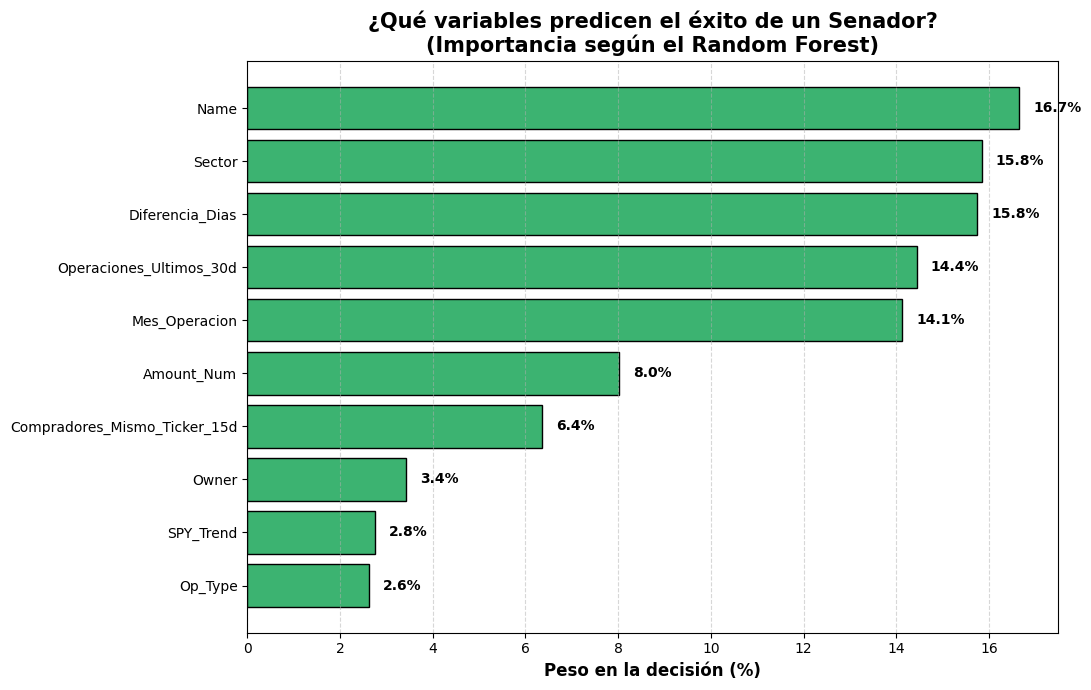


--- RESUMEN DEL DATASET VÁLIDO ---
Operaciones limpias analizadas: 11205
Tasa base de éxito (Operaciones que batieron al S&P500): 48.8%


In [4]:
# ==============================================================================
# 3. TRADUCCIÓN PARA LA MÁQUINA (PREPROCESSING)
# ==============================================================================
print("3. Preparando los datos para la Inteligencia Artificial...")

# --- EL TORNIQUETE SALVAVIDAS ---
# Rellenamos los vacíos de Owner asumiendo que son operaciones propias (Self)
df['Owner'] = df['Owner'].fillna('Self')
# --------------------------------

# Nos quedamos solo con las columnas buenas y sin nulos vitales
columnas_necesarias = [
    'Return_19d', 'Return_SPY_19d', 'Sector', 'Amount_Num', 
    'Diferencia_Dias', 'SPY_Trend', 'Name', 'Owner', 'Op_Type',
    'Operaciones_Ultimos_30d', 'Compradores_Mismo_Ticker_15d', 'Mes_Operacion'
]
df_ml = df.dropna(subset=columnas_necesarias).copy()

# NUESTRO OBJETIVO: 1 = Ganar al SP500, 0 = Perder contra el SP500
df_ml['Exito'] = np.where(df_ml['Return_19d'] > df_ml['Return_SPY_19d'], 1, 0)

# Las "X" (Pistas) y la "y" (Respuesta)
features = [
    'Amount_Num', 'Diferencia_Dias', 'Operaciones_Ultimos_30d', 
    'Compradores_Mismo_Ticker_15d', 'SPY_Trend', 'Mes_Operacion', 
    'Sector', 'Name', 'Owner', 'Op_Type'
]
X = df_ml[features].copy()
y = df_ml['Exito']

# Traducir los textos a números usando LabelEncoder
codificadores = {}
columnas_texto = ['Sector', 'Name', 'Owner', 'Op_Type']

for col in columnas_texto:
    le = LabelEncoder()
    # Convertimos a string primero para mayor seguridad
    X[col] = le.fit_transform(X[col].astype(str))
    codificadores[col] = le

# ==============================================================================
# 4. ENTRENAMIENTO DEL RANDOM FOREST Y RESULTADOS
# ==============================================================================
print("4. Entrenando al Bosque Aleatorio...")
# 200 árboles de decisión, profundidad máxima 7 para que no haga "trampas" memorizando
modelo_rf = RandomForestClassifier(n_estimators=1500, random_state=42, max_depth=7)
modelo_rf.fit(X, y)

# Extraer el conocimiento de la IA
importancias = modelo_rf.feature_importances_
df_importancias = pd.DataFrame({'Variable': features, 'Importancia': importancias * 100})
df_importancias = df_importancias.sort_values('Importancia', ascending=True)

# DIBUJAR EL GRÁFICO
plt.figure(figsize=(11, 7))
plt.barh(df_importancias['Variable'], df_importancias['Importancia'], color='mediumseagreen', edgecolor='black')
plt.xlabel('Peso en la decisión (%)', fontsize=12, fontweight='bold')
plt.title('¿Qué variables predicen el éxito de un Senador?\n(Importancia según el Random Forest)', fontsize=15, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Poner los numeritos en cada barra
for index, value in enumerate(df_importancias['Importancia']):
    plt.text(value + 0.3, index, f'{value:.1f}%', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Resumen final de datos
print(f"\n--- RESUMEN DEL DATASET VÁLIDO ---")
print(f"Operaciones limpias analizadas: {len(df_ml)}")
print(f"Tasa base de éxito (Operaciones que batieron al S&P500): {(y.mean()*100):.1f}%")

In [5]:
# ==============================================================================
# EXPLORACIÓN DE DIRECCIONALIDAD: ¿Qué valores exactos dan dinero?
# ==============================================================================
import pandas as pd

df_analisis = df_ml.copy()

print("--- TOP 5 SECTORES MÁS RENTABLES (Min. 30 operaciones) ---")
# Usamos 'Sector' directamente porque ya tiene el texto original
sectores = df_analisis.groupby('Sector')['Exito'].agg(['mean', 'count'])
sectores = sectores[sectores['count'] >= 30].sort_values('mean', ascending=False)
sectores['Win Rate'] = (sectores['mean'] * 100).round(1).astype(str) + '%'
print(sectores[['count', 'Win Rate']].head(5))

print("\n--- ANÁLISIS DE RETRASO (Diferencia_Dias) ---")
# Agrupamos los días de retraso en bloques razonables
bins = [-1, 5, 15, 30, 45, 999]
labels = ['0-5 días (Rápido)', '6-15 días', '16-30 días', '31-45 días (Límite)', '+45 días (Multa)']
df_analisis['Dias_Rango'] = pd.cut(df_analisis['Diferencia_Dias'], bins=bins, labels=labels)

retraso = df_analisis.groupby('Dias_Rango', observed=True)['Exito'].agg(['mean', 'count'])
retraso['Win Rate'] = (retraso['mean'] * 100).round(1).astype(str) + '%'
print(retraso[['count', 'Win Rate']])

print("\n--- TOP 5 SENADORES CON MEJOR WIN RATE (Min. 20 operaciones) ---")
# Usamos 'Name' directamente porque ya tiene el nombre original
senadores = df_analisis.groupby('Name')['Exito'].agg(['mean', 'count'])
senadores = senadores[senadores['count'] >= 20].sort_values('mean', ascending=False)
senadores['Win Rate'] = (senadores['mean'] * 100).round(1).astype(str) + '%'
print(senadores[['count', 'Win Rate']].head(5))

--- TOP 5 SECTORES MÁS RENTABLES (Min. 30 operaciones) ---
                    count Win Rate
Sector                            
Basic Materials       346    53.8%
Real Estate           337    53.1%
Technology           2242    52.0%
Financial Services   1373    51.9%
Energy                758    51.5%

--- ANÁLISIS DE RETRASO (Diferencia_Dias) ---
                     count Win Rate
Dias_Rango                         
0-5 días (Rápido)     3704    50.2%
6-15 días             2440    46.8%
16-30 días            3130    49.1%
31-45 días (Límite)    828    47.9%
+45 días (Multa)      1103    48.6%

--- TOP 5 SENADORES CON MEJOR WIN RATE (Min. 20 operaciones) ---
                                         count Win Rate
Name                                                   
Hon. C. Scott Franklin                      33    75.8%
Hon. David J. Taylor                        35    71.4%
Hon. John James                            118    71.2%
Hon. Donald Sternoff Honorable Beyer Jr     43    6

In [6]:
# ==============================================================================
# EL BACKTEST DEFINITIVO: APLICANDO LAS REGLAS DE ORO (AUTOMATIZADO)
# ==============================================================================

# 1. BÚSQUEDA AUTOMÁTICA DE LOS "LOBOS"
# Calculamos el win rate de cada senador en la base de datos
stats_senadores = df_analisis.groupby('Name')['Exito'].agg(['mean', 'count'])
# Le pedimos al código que filtre solo a los que tienen >= 20 operaciones y > 64% de acierto
lobos_detectados = stats_senadores[(stats_senadores['count'] >= 20) & (stats_senadores['mean'] >= 0.58)]
top_senadores = lobos_detectados.index.tolist() # Sacamos la lista de nombres automáticamente

print(f"🐺 Lobos detectados automáticamente ({len(top_senadores)} senadores):")
for lobo in top_senadores:
    print(f"  - {lobo} (Win Rate: {lobos_detectados.loc[lobo, 'mean']*100:.1f}%)")
print("-" * 50)

# 2. DEFINIMOS LOS FILTROS
filtro_lobos = df_analisis['Name'].isin(top_senadores)
# Añadimos Real Estate a nuestra lista de sectores premium
filtro_sectores = df_analisis['Sector'].isin(['Energy', 'Real Estate']) 
filtro_impacientes_ocultos = (df_analisis['Diferencia_Dias'] <= 5) | (df_analisis['Diferencia_Dias'] >= 45)

# --- REGLA 1: Solo copiar a los Lobos ---
ops_lobos = df_analisis[filtro_lobos]
wr_lobos = ops_lobos['Exito'].mean() * 100

# --- REGLA 2: Solo comprar Sectores Premium ---
ops_sectores = df_analisis[filtro_sectores]
wr_sectores = ops_sectores['Exito'].mean() * 100

# --- REGLA 3: El Combo Letal (Sectores Premium + Delay sospechoso) ---
ops_combo = df_analisis[filtro_sectores & filtro_impacientes_ocultos]
wr_combo = ops_combo['Exito'].mean() * 100

# --- REGLA 4: EL FILTRO MAESTRO (O es un Lobo, O es el Combo Letal) ---
filtro_maestro = filtro_lobos | (filtro_sectores & filtro_impacientes_ocultos)
ops_maestras = df_analisis[filtro_maestro]
wr_maestro = ops_maestras['Exito'].mean() * 100


# Imprimir los resultados del Backtest
print("\n========== RESULTADOS DEL ALGORITMO DE TRADING ==========\n")
print(f"Base del Congreso (Comprar todo a ciegas): 50.4% de éxito\n")

print(f"ESTRATEGIA 1: Copiar solo a los {len(top_senadores)} Lobos")
print(f" -> Operaciones encontradas: {len(ops_lobos)}")
print(f" -> Nuevo Win Rate: {wr_lobos:.1f}%\n")

print(f"ESTRATEGIA 2: Comprar 'Energy' y 'Real Estate'")
print(f" -> Operaciones encontradas: {len(ops_sectores)}")
print(f" -> Nuevo Win Rate: {wr_sectores:.1f}%\n")

print(f"ESTRATEGIA 3: Combo Sospechoso (Sectores Premium + Delay <5 o >45)")
print(f" -> Operaciones encontradas: {len(ops_combo)}")
print(f" -> Nuevo Win Rate: {wr_combo:.1f}%\n")

print(f"🏆 ESTRATEGIA FINAL: El Filtro Maestro Actualizado")
print(f" -> Operaciones encontradas: {len(ops_maestras)}")
print(f" -> Win Rate Definitivo: {wr_maestro:.1f}%")
print("=========================================================")

🐺 Lobos detectados automáticamente (12 senadores):
  - Hon. C. Scott Franklin (Win Rate: 75.8%)
  - Hon. Christopher L. Jacobs (Win Rate: 62.0%)
  - Hon. David J. Taylor (Win Rate: 71.4%)
  - Hon. Donald Sternoff Honorable Beyer Jr (Win Rate: 69.8%)
  - Hon. James Comer (Win Rate: 62.1%)
  - Hon. John James (Win Rate: 71.2%)
  - Hon. Julie Johnson (Win Rate: 62.5%)
  - Hon. Mark Dr Green (Win Rate: 61.7%)
  - Hon. Nancy Pelosi (Win Rate: 61.9%)
  - Hon. Tim Moore (Win Rate: 62.1%)
  - Hon. Victoria Spartz (Win Rate: 61.9%)
  - Mrs. Marjorie Taylor Greene (Win Rate: 59.1%)
--------------------------------------------------

========== RESULTADOS DEL ALGORITMO DE TRADING ==========

Base del Congreso (Comprar todo a ciegas): 50.4% de éxito

ESTRATEGIA 1: Copiar solo a los 12 Lobos
 -> Operaciones encontradas: 733
 -> Nuevo Win Rate: 64.9%

ESTRATEGIA 2: Comprar 'Energy' y 'Real Estate'
 -> Operaciones encontradas: 1095
 -> Nuevo Win Rate: 52.0%

ESTRATEGIA 3: Combo Sospechoso (Sectores P

In [11]:
# ==============================================================================
# SIMULADOR DE CARTERA: $10k INICIALES, $1k POR TRADE VS HOLD S&P500
# ==============================================================================

#SI USAMOS SOLO LAS OPERACIONES DE LOS LOBOS DA MEJOR RENDIMIENTO

# Usamos las operaciones de nuestra ESTRATEGIA FINAL (Filtro Maestro)
ops = ops_maestras.copy()
ops = ops[ops['Buy_Date'].dt.year >= 2020]

ops = ops.sort_values('Buy_Date')

# Identificamos los años que tenemos en el dataset (2022, 2023, 2024...)
years = sorted(ops['Buy_Date'].dt.year.dropna().unique())

resultados_backtest = []
cash = 10000.0  # Empezamos el año con 10k
capital_spy_final = 10000.0

for year in years:
    # Filtramos las operaciones de ese año en concreto
    df_year = ops[ops['Buy_Date'].dt.year == year].copy()
    
    # --- 1. SIMULACIÓN DE NUESTRA ESTRATEGIA ---
    #cash = 10000.0  # Empezamos el año con 10k
    tamaño_posicion = 1000.0
    operaciones_abiertas = []
    
    trades_ejecutados = 0
    trades_rechazados_liquidez = 0
    
    # Creamos una línea temporal con todos los días donde compramos o vendemos algo
    fechas_eventos = set(df_year['Buy_Date'].tolist() + df_year['Sell_Date'].tolist())
    fechas_eventos = sorted(list(fechas_eventos))
    
    for fecha in fechas_eventos:
        # A) PROCESAR VENTAS PRIMERO (Liberar liquidez)
        ventas_hoy = [op for op in operaciones_abiertas if op['fecha_venta'] == fecha]
        # Dejamos en la lista solo las que aún NO han vencido
        operaciones_abiertas = [op for op in operaciones_abiertas if op['fecha_venta'] > fecha]
        
        for venta in ventas_hoy:
            # Recuperamos los 1000$ más la rentabilidad de esos 19 días
            cash += tamaño_posicion * (1 + venta['retorno'])
            
        # B) PROCESAR COMPRAS (Nuevas señales)
        compras_hoy = df_year[df_year['Buy_Date'] == fecha]
        for _, row in compras_hoy.iterrows():
            # Si nos quedan al menos 1000$ en efectivo, ejecutamos la compra
            if cash >= tamaño_posicion:
                cash -= tamaño_posicion
                operaciones_abiertas.append({
                    'fecha_venta': row['Sell_Date'],
                    'retorno': row['Return_19d']
                })
                trades_ejecutados += 1
            else:
                # Si tenemos el dinero bloqueado en otras operaciones, nos perdemos esta
                trades_rechazados_liquidez += 1
                
    # A final de año, sumamos el cash sobrante y el valor actual de los trades aún abiertos
    valor_operaciones_abiertas = sum([tamaño_posicion * (1 + op['retorno']) for op in operaciones_abiertas])
    capital_estrategia_final = cash + valor_operaciones_abiertas
    
    # --- 2. SIMULACIÓN BENCHMARK (S&P 500 BUY & HOLD) ---
    try:
        spy_year = hist_data['SPY'][hist_data['SPY'].index.year == year].dropna()
        if not spy_year.empty:
            rentabilidad_spy = (spy_year.iloc[-1] - spy_year.iloc[0]) / spy_year.iloc[0]
        else:
            rentabilidad_spy = 0
    except:
        rentabilidad_spy = 0
        
    capital_spy_final = capital_spy_final * (1 + rentabilidad_spy)
    
    # Guardar resultados del año
    resultados_backtest.append({
        'Año': int(year),
        'Trades Ejecutados': trades_ejecutados,
        'Trades Sin Dinero': trades_rechazados_liquidez,
        'S&P 500 ($)': round(capital_spy_final, 2),
        'Estrategia ($)': round(capital_estrategia_final, 2),
        'Diferencia ($)': round(capital_estrategia_final - capital_spy_final, 2)
    })

# --- MOSTRAR RESULTADOS GLOBALES ---
df_resultados = pd.DataFrame(resultados_backtest)
df_resultados.set_index('Año', inplace=True)

print("================================================================")
print("💰 SIMULADOR DE CARTERA: $10,000 Iniciales cada año ($1k x Trade)")
print("================================================================\n")
print(df_resultados.to_string())

# Matemáticas acumuladas de todos los años
beneficio_estrategia = df_resultados['Estrategia ($)'].sum() - (10000 * len(years))
beneficio_spy = df_resultados['S&P 500 ($)'].sum() - (10000 * len(years))

print(f"\n📈 RESUMEN DE TODOS LOS AÑOS COMBINADOS:")
print(f" -> Beneficio Neto Estrategia: ${beneficio_estrategia:,.2f}")
print(f" -> Beneficio Neto S&P 500: ${beneficio_spy:,.2f}")
if beneficio_estrategia > beneficio_spy:
    print(f"🏆 ¡La estrategia superó al S&P 500 generando ${beneficio_estrategia - beneficio_spy:,.2f} extra!")
else:
    print(f"📉 El mercado tradicional ganó esta vez.")

💰 SIMULADOR DE CARTERA: $10,000 Iniciales cada año ($1k x Trade)

      Trades Ejecutados  Trades Sin Dinero  S&P 500 ($)  Estrategia ($)  Diferencia ($)
Año                                                                                    
2020                 86                 26     11723.52         9916.30        -1807.22
2021                172                 81     15299.84        14702.78         -597.06
2022                146                 22     12446.97        17085.33         4638.36
2023                 72                  2     15771.46        18828.54         3057.08
2024                 63                127     19807.26        20097.15          289.88
2025                200                155     23374.35        24823.31         1448.95

📈 RESUMEN DE TODOS LOS AÑOS COMBINADOS:
 -> Beneficio Neto Estrategia: $45,453.41
 -> Beneficio Neto S&P 500: $38,423.40
🏆 ¡La estrategia superó al S&P 500 generando $7,030.01 extra!


Calculando la evolución diaria de tu fondo... (Esto puede tardar unos segundos)


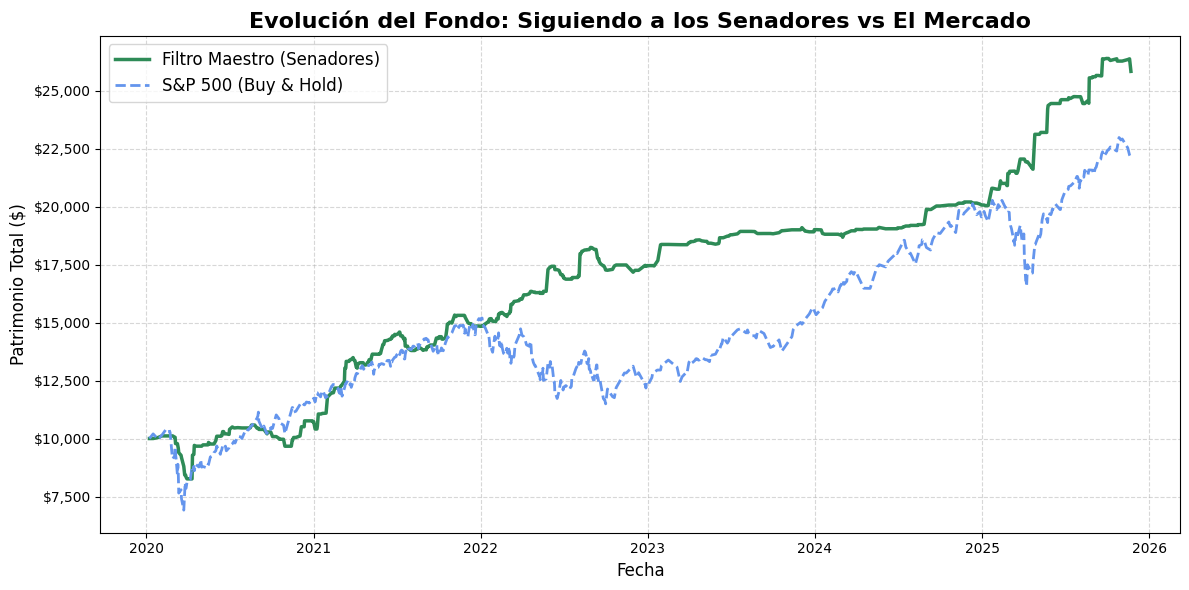

💰 RESUMEN DEL FONDO (Desde 2020-01-08 hasta Hoy):
 -> Capital Final Estrategia : $25,830.85
 -> Capital Final S&P 500    : $22,100.81
 -> Beneficio respecto SP500 : $3,730.03


In [12]:
# ==============================================================================
# SIMULADOR DE CARTERA CONTINUO Y GRÁFICO DE EVOLUCIÓN (EQUITY CURVE)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Filtramos las operaciones de 2022 en adelante
ops = ops_maestras[ops_maestras['Buy_Date'].dt.year >= 2020].copy()
ops = ops.sort_values('Buy_Date')

# 2. Configuración Inicial del Fondo
capital_inicial = 10000.0
cash = capital_inicial
tamaño_posicion = 750.0
operaciones_abiertas = []

historial_curva = []

# Calculamos cuántas acciones del SPY podríamos haber comprado el primer día con 10k
fecha_inicio = ops['Buy_Date'].min()
precio_spy_inicio = get_price('SPY', fecha_inicio, 'forward')
acciones_spy_benchmark = capital_inicial / precio_spy_inicio if pd.notna(precio_spy_inicio) else 0

# Creamos una línea temporal con absolutamente todos los días donde pasa algo (compra o venta)
fechas_eventos = sorted(list(set(ops['Buy_Date'].tolist() + ops['Sell_Date'].tolist())))

print("Calculando la evolución diaria de tu fondo... (Esto puede tardar unos segundos)")

for fecha in fechas_eventos:
    # A) PROCESAR VENTAS PRIMERO (Recogemos beneficios y liberamos liquidez)
    ventas_hoy = [op for op in operaciones_abiertas if op['fecha_venta'] == fecha]
    operaciones_abiertas = [op for op in operaciones_abiertas if op['fecha_venta'] > fecha]
    
    for venta in ventas_hoy:
        cash += tamaño_posicion * (1 + venta['retorno'])
        
    # B) PROCESAR COMPRAS (Nuevas alertas de los Senadores)
    compras_hoy = ops[ops['Buy_Date'] == fecha]
    for _, row in compras_hoy.iterrows():
        # Si tenemos al menos $1000 libres, disparamos la operación
        if cash >= tamaño_posicion:
            cash -= tamaño_posicion
            operaciones_abiertas.append({
                'fecha_venta': row['Sell_Date'],
                'retorno': row['Return_19d']
            })

    # C) CALCULAR PATRIMONIO TOTAL ESE DÍA
    # El patrimonio es el Cash libre + el dinero que tenemos "congelado" en el mercado
    valor_operaciones = len(operaciones_abiertas) * tamaño_posicion
    capital_total = cash + valor_operaciones
    
    # D) CALCULAR VALOR DEL S&P 500 ESE MISMO DÍA PARA COMPARAR
    precio_spy_hoy = get_price('SPY', fecha, 'nearest')
    valor_spy = acciones_spy_benchmark * precio_spy_hoy if pd.notna(precio_spy_hoy) else np.nan
    
    # Guardamos la "foto" del día
    historial_curva.append({
        'Fecha': fecha,
        'Estrategia_Senadores': capital_total,
        'SP500_Hold': valor_spy
    })

# 3. DIBUJAR LA CURVA DE CAPITAL
df_curva = pd.DataFrame(historial_curva).dropna()
df_curva.set_index('Fecha', inplace=True)

plt.figure(figsize=(12, 6))
# Nuestra estrategia en verde oscuro
plt.plot(df_curva.index, df_curva['Estrategia_Senadores'], label='Filtro Maestro (Senadores)', color='seagreen', linewidth=2.5)
# El mercado general en azul punteado
plt.plot(df_curva.index, df_curva['SP500_Hold'], label='S&P 500 (Buy & Hold)', color='cornflowerblue', linewidth=2, linestyle='--')

plt.title('Evolución del Fondo: Siguiendo a los Senadores vs El Mercado', fontsize=16, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Patrimonio Total ($)', fontsize=12)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

# Formatear el eje Y con el símbolo de Dólar
formatter = plt.FuncFormatter(lambda x, loc: "${:,.0f}".format(x))
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

print("================================================================")
print(f"💰 RESUMEN DEL FONDO (Desde {fecha_inicio.strftime('%Y-%m-%d')} hasta Hoy):")
print(f" -> Capital Final Estrategia : ${df_curva['Estrategia_Senadores'].iloc[-1]:,.2f}")
print(f" -> Capital Final S&P 500    : ${df_curva['SP500_Hold'].iloc[-1]:,.2f}")
print(f" -> Beneficio respecto SP500 : ${(df_curva['Estrategia_Senadores'].iloc[-1]-df_curva['SP500_Hold'].iloc[-1]):,.2f}")
print("================================================================")